In [85]:
import numpy as np

import smplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import astropy.units as u
from astropy.constants import L_sun
from astropy.cosmology import FlatLambdaCDM

import fsps
from sedpy.observate import getSED, load_filters
from specconvert import convert_flux, convert_wave, MAGGIE_UNIT, FLAM_CGS


In [86]:
plt.rcParams.update({"font.style": "normal", "mathtext.default": "rm"})

# Define cosmology and sampling settings.
COSMO = FlatLambdaCDM(H0=67.4, Om0=0.315)

N_REDSHIFT_SAMPLES = 100
N_SFH_SAMPLES = 1000  # Resolution of the analytic diagnostic plot grid.
N_MOCKS_PER_REDSHIFT = 20
RANDOM_SEED = 42
T_MIN_GYR = 0.03
TAU_MIN_GYR = 0.01

# Initialise FSPS
sp = fsps.StellarPopulation(
    sfh=4,
    zcontinuous=1,
    logzsol=0.0,
    imf_type=2,
    const=0.0,
    fburst=0.0,
    sf_trunc=0.0,
    add_neb_emission=False,
)


In [87]:
def make_delayed_tau_sfh(z, t_galaxy, tau, logmass, logzsol=0.0,
                         sp=sp, cosmo=COSMO, n_time=500):
    """Return an FSPS delayed-tau model normalized to target surviving mass.

    Ages and times are in Gyr, masses in Msun, and SFR in Msun/yr.
    The spectrum is rest-frame Lsun/Angstrom and sSFR is in yr^-1.
    """

    # Cosmic time at observation and onset of star formation.
    t_obs = cosmo.age(z).to_value(u.Gyr)
    t_form = t_obs - t_galaxy

    if t_galaxy <= 0 or t_galaxy > t_obs:
        raise ValueError("Galaxy age must be positive and <= cosmic age.")

    if tau <= 0:
        raise ValueError("tau must be positive.")

    # Set the FSPS parameters.
    sp.params["sfh"] = 4
    sp.params["tau"] = tau
    sp.params["sf_start"] = t_form
    sp.params["sf_trunc"] = 0.0
    sp.params["const"] = 0.0
    sp.params["fburst"] = 0.0
    sp.params["logzsol"] = logzsol

    # Calculate the spectrum at the observation time.
    wave, spec_unit = sp.get_spectrum(tage=t_obs, peraa=True)

    # FSPS normalisation: quantities for one Msun of formed stellar mass.
    Mstar_unit = sp.stellar_mass
    Mformed_unit = sp.formed_mass
    SFR_unit = sp.sfr

    # Normalise to the desired surviving stellar mass.
    Mstar_target = 10**logmass
    norm = Mstar_target / Mstar_unit

    # Physical properties after normalisation.
    Mstar = Mstar_unit * norm
    Mformed = Mformed_unit * norm
    SFR = SFR_unit * norm
    sSFR = SFR_unit / Mstar_unit

    # Generate a time-resolved SFH for the catalogue.
    n_time = max(n_time, int(np.ceil(50.0 * t_galaxy / tau)) + 1)
    t_gal = np.linspace(0.0, t_galaxy, n_time)

    # Dimensionless delayed-tau shape and its exact integral in years.
    sfh_shape = (t_gal / tau) * np.exp(-t_gal / tau)
    x_end = t_galaxy / tau
    integral = tau * 1e9 * (1.0 - (1.0 + x_end) * np.exp(-x_end))
    sfr_history = Mformed * sfh_shape / integral

    # Convert to cosmic time.
    cosmic_time = t_form + t_gal

    return {
        "z": z,
        "t_form": t_form,
        "t_galaxy": t_galaxy,
        "tau": tau,
        "logMstar": logmass,
        "logzsol": logzsol,
        "time": cosmic_time,
        "time_since_formation": t_gal,
        "sfr_history": sfr_history,
        "wave": wave,
        "spectrum": spec_unit * norm,
        "Mstar": Mstar,
        "Mformed": Mformed,
        "SFR": SFR,
        "sSFR": sSFR,
    }


def ssfr_quenching_threhsold(z, ssfr_threshold=0.2, cosmo=COSMO):
    """Return the sSFR cut ``ssfr_threshold / cosmic_age`` in yr^-1."""
    return ssfr_threshold / cosmo.age(z).to_value(u.yr)


def is_quiescent_fsps(model, z, ssfr_threshold=0.2, cosmo=COSMO):
    """Check FSPS sSFR against the redshift-dependent quiescence cut."""
    return model["sSFR"] < ssfr_quenching_threhsold(z, ssfr_threshold, cosmo)


def find_quiescent_tau_max(z, t_galaxy, logmass=10.5, logzsol=0.0,
                           quiescence_check=is_quiescent_fsps, tau_min=TAU_MIN_GYR,
                           sp=sp, cosmo=COSMO, n_time=500, n_bisection=24):
    """Find the passing-side tau maximum, assuming one allowed interval from tau_min.

    Return None when tau_min fails; the callback accepts ``(model, z, cosmo=...)``.
    """
    t_obs = cosmo.age(z).to_value(u.Gyr)
    if t_galaxy > t_obs:
        raise ValueError("Galaxy age cannot exceed the cosmic age.")

    model_min = make_delayed_tau_sfh(z, t_galaxy, tau_min, logmass, logzsol=logzsol, sp=sp, cosmo=cosmo, n_time=n_time)
    if not quiescence_check(model_min, z, cosmo=cosmo):
        return None

    tau_fail = t_obs
    model_fail = make_delayed_tau_sfh(z, t_galaxy, tau_fail, logmass, logzsol=logzsol, sp=sp, cosmo=cosmo, n_time=n_time)
    if quiescence_check(model_fail, z, cosmo=cosmo):
        raise RuntimeError(
            f"Quiescence criterion still passes at tau=t_age={t_obs:.4g} Gyr for z={z}, "
            f"t={t_galaxy:.4g} Gyr; no failing endpoint brackets the upper boundary."
        )

    tau_pass = tau_min
    for _ in range(n_bisection):
        tau_mid = 0.5 * (tau_pass + tau_fail)
        model_mid = make_delayed_tau_sfh(z, t_galaxy, tau_mid, logmass, logzsol=logzsol, sp=sp, cosmo=cosmo, n_time=n_time)
        if quiescence_check(model_mid, z, cosmo=cosmo):
            tau_pass = tau_mid
        else:
            tau_fail = tau_mid
    return tau_pass


def sample_quiescent_models(z, n_models=N_MOCKS_PER_REDSHIFT, logmass=10.5,
                            logzsol=0.0, quiescence_check=is_quiescent_fsps,
                            t_min=T_MIN_GYR, tau_min=TAU_MIN_GYR, rng=None,
                            sp=sp, cosmo=COSMO, n_time=500, max_age_draws=None):
    """Draw uniform ages, then uniform tau within each age's allowed interval.

    Ages are uniform over the feasible range, rejecting only when tau_min fails.
    The check callback accepts
    ``(model, z, cosmo=...)``; ``max_age_draws`` prevents an endless search.
    """
    if rng is None:
        rng = np.random.default_rng()
    t_obs = cosmo.age(z).to_value(u.Gyr)
    if t_min >= t_obs:
        raise ValueError(f"t_min={t_min} Gyr must be below the cosmic age at z={z}.")

    accepted = []
    if max_age_draws is None:
        max_age_draws = 100 * n_models
    age_draws = 0
    while len(accepted) < n_models and age_draws < max_age_draws:
        age_draws += 1
        t_galaxy = rng.uniform(t_min, t_obs)
        tau_max = find_quiescent_tau_max(
            z, t_galaxy, logmass=logmass, logzsol=logzsol, quiescence_check=quiescence_check,
            tau_min=tau_min, sp=sp, cosmo=cosmo, n_time=n_time,
        )
        # Reject only ages for which even tau_min is not quiescent.
        if tau_max is None:
            continue

        tau = rng.uniform(tau_min, tau_max)
        model = make_delayed_tau_sfh(
            z, t_galaxy, tau, logmass, logzsol=logzsol, sp=sp, cosmo=cosmo, n_time=n_time,
        )
        if not quiescence_check(model, z, cosmo=cosmo):
            raise RuntimeError("A sampled tau failed the same quiescence predicate used for its bound.")
        model["tau_max_gyr"] = tau_max
        accepted.append(model)
    if len(accepted) < n_models:
        raise RuntimeError(f"Found {len(accepted)} of {n_models} accepted models in {max_age_draws} age draws at z={z}.")
    return accepted


# Wang et al. 2024, ApJL 969 L13, https://doi.org/10.3847/2041-8213/ad55f7.
def calculate_wang24_spectral_break(rest_wave_aa, flambda):
    """Return the red-to-blue median intrinsic F_lambda ratio in Wang+24 windows."""
    red = (rest_wave_aa >= 4000) & (rest_wave_aa <= 4100)
    blue = (rest_wave_aa >= 3620) & (rest_wave_aa <= 3720)
    return np.median(flambda[red]) / np.median(flambda[blue])


def build_mock_sed(model, filters, filter_labels, cosmo=COSMO):
    """Add observed-frame spectrum, photometry and colours to a scaled model.

    Reuses the existing mass-normalised spectrum; ``cosmo`` sets luminosity distance.
    """
    z_obs = model["z"]
    wave_rest_aa = np.asarray(model["wave"])
    lum_rest_cgs_per_aa = np.asarray(model["spectrum"]) * L_sun.to("erg / s").value
    wave_obs_aa = wave_rest_aa * (1.0 + z_obs)
    lum_distance_cm = cosmo.luminosity_distance(z_obs).to_value(u.cm)
    flux_obs_cgs_per_aa = lum_rest_cgs_per_aa / (4.0 * np.pi * lum_distance_cm**2 * (1.0 + z_obs))

    sed_abmag = np.asarray(getSED(wave_obs_aa, flux_obs_cgs_per_aa, filters))
    sed_maggies = np.asarray(getSED(wave_obs_aa, flux_obs_cgs_per_aa, filters, linear_flux=True))
    filter_wave_aa = np.array([band.wave_effective for band in filters])
    sed_flambda_cgs, _ = convert_flux(sed_maggies, MAGGIE_UNIT, FLAM_CGS, wave=filter_wave_aa * u.AA)
    photometry = {
        label: {"wave_eff_aa": wave_eff, "abmag": mag, "maggies": maggies, "f_lambda_cgs_per_aa": flambda}
        for label, wave_eff, mag, maggies, flambda in zip(filter_labels, filter_wave_aa, sed_abmag, sed_maggies, sed_flambda_cgs)
    }
    abmag_dict = dict(zip(filter_labels, sed_abmag))
    model.update({
        "wave_rest_aa": wave_rest_aa,
        "wave_obs_aa": wave_obs_aa,
        "flux_obs_cgs_per_aa": flux_obs_cgs_per_aa,
        "filter_wave_aa": filter_wave_aa,
        "sed_abmag": sed_abmag,
        "sed_maggies": sed_maggies,
        "sed_f_lambda_cgs_per_aa": sed_flambda_cgs,
        "photometry": photometry,
        "colors": {
            "f150w2": (abmag_dict["F150W2"] - abmag_dict["F277W"], abmag_dict["F277W"] - abmag_dict["F444W"]),
        },
        "balmer_break_colour_mag": abmag_dict["F150W2"] - abmag_dict["F277W"],
        "balmer_break_wang24_flambda_ratio": calculate_wang24_spectral_break(wave_rest_aa, np.asarray(model["spectrum"])),
    })
    return model


In [88]:
def ssfr_delayed_tau(t, tau):
    """Return SFR/Mformed in inverse units of ``t``; ``tau`` uses the same units."""
    x = t / tau
    ssfr = x**2 / (t * (np.exp(x) - 1 - x))
    return ssfr


def select_quiescent_sfhs(z, t_vals, tau_vals, ssfr_threshold=0.2, cosmo=COSMO, return_mask=False):
    """Return analytic formed-mass sSFR pairs below the cosmic-age cut.

    ``t_vals`` and ``tau_vals`` are Gyr arrays. With ``return_mask=True``,
    return a ``(len(t_vals), len(tau_vals))`` boolean grid.
    """
    ssfr_threshold_value = ssfr_quenching_threhsold(z, ssfr_threshold, cosmo)

    # Match the threshold units of inverse years.
    ssfr_values = ssfr_delayed_tau(t_vals[:, np.newaxis] * 1e9, tau_vals[np.newaxis, :] * 1e9)
    physical_ages = t_vals[:, np.newaxis] <= cosmo.age(z).to_value(u.Gyr)
    quiescent_mask = (ssfr_values < ssfr_threshold_value) & physical_ages

    if return_mask:
        return quiescent_mask

    # Preserve the valid pairings rather than projecting each axis independently.
    t_indices, tau_indices = np.nonzero(quiescent_mask)
    return t_vals[t_indices], tau_vals[tau_indices]


In [89]:
# Redshift range and analytic diagnostic grid.
z_min = 3.0
z_max = 6.0
z_vals = np.linspace(z_min, z_max, N_REDSHIFT_SAMPLES)

# This analytic grid is a visual preselection only; final selection uses FSPS surviving mass.
tau_vals = np.linspace(TAU_MIN_GYR, 1.0, N_SFH_SAMPLES)
t_vals = np.linspace(T_MIN_GYR, COSMO.age(z_min).to_value(u.Gyr), N_SFH_SAMPLES)


In [90]:
ssfr_thresholds = ssfr_quenching_threhsold(z_vals)
logssfr_thresholds = np.log10(ssfr_thresholds)

In [92]:
FILTER_NAMES = ["jwst_f150w2", "jwst_f277w", "jwst_f444w"]
FILTER_LABELS = ["F150W2", "F277W", "F444W"]
filters = load_filters(FILTER_NAMES)

rng = np.random.default_rng(RANDOM_SEED)
mock_models = {
    z: [build_mock_sed(model, filters, FILTER_LABELS) for model in sample_quiescent_models(z, rng=rng)]
    for z in np.arange(z_min, z_max + 1, 1, dtype=float)
}


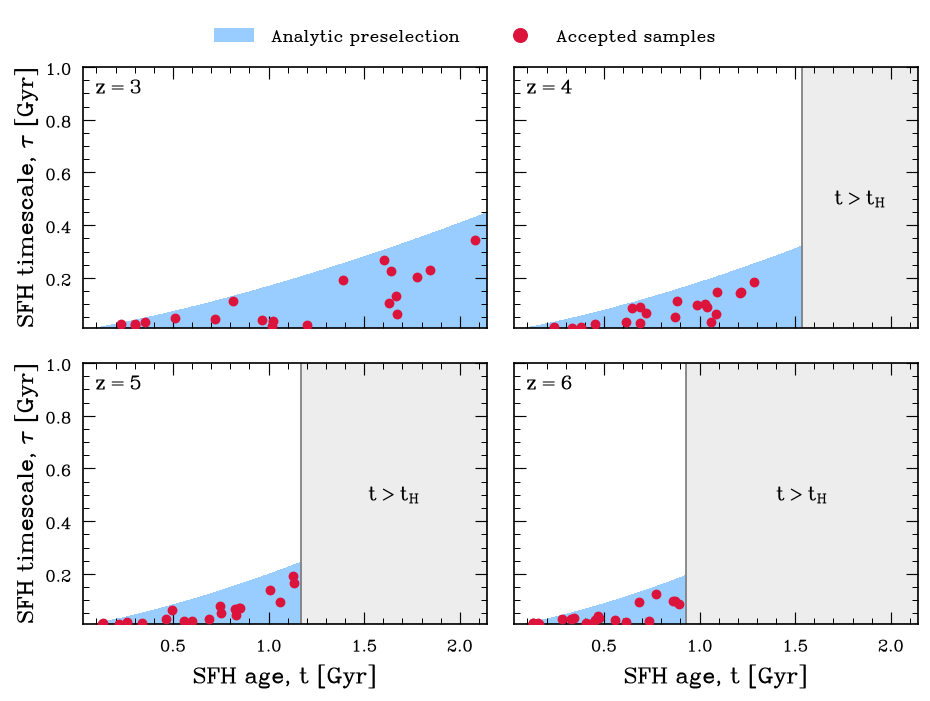

In [98]:
# Show four redshifts spanning z = 3 to 6.
z_panels = np.linspace(z_min, z_max, 4)
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)

for ax, z in zip(axes.flat, z_panels):
    quiescent_mask = select_quiescent_sfhs(z, t_vals, tau_vals, return_mask=True)
    cosmic_age = COSMO.age(z).to_value(u.Gyr)

    # Transpose because mask rows index t and columns index tau.
    ax.contourf(t_vals, tau_vals, quiescent_mask.T.astype(float), levels=[0.5, 1.5], colors=["dodgerblue"], alpha=0.45)
    ax.scatter([m["t_galaxy"] for m in mock_models[z]], [m["tau"] for m in mock_models[z]], color="crimson", s=24, marker="o", zorder=4)
    if cosmic_age < t_vals.max():
        ax.axvspan(cosmic_age, t_vals.max(), facecolor="lightgray", edgecolor="gray", alpha=0.4)
        ax.axvline(cosmic_age, color="gray", lw=1)
        
        x_mid = 0.5 * (cosmic_age + t_vals.max())
        ax.text(x_mid, 0.5, r"$t > t_{\mathrm{H}}$", fontsize=14,
                transform=ax.get_xaxis_transform(), va="center", ha="center")

    ax.text(0.03, 0.97, rf"$z = {z:.0f}$", fontsize=14, transform=ax.transAxes, va="top", ha="left")
    ax.set_xlim(t_vals.min(), t_vals.max())
    ax.set_ylim(tau_vals.min(), tau_vals.max())
    ax.tick_params(labelsize=12)

for ax in axes[-1, :]:
    ax.set_xlabel(r"SFH age, $t$ [Gyr]", fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel(r"SFH timescale, $\tau$ [Gyr]", fontsize=16)

legend_handles = [Patch(facecolor="dodgerblue", alpha=0.45, label="Analytic preselection"), plt.Line2D([], [], color="crimson", marker="o", linestyle="None", label="Accepted samples")]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=False, fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])


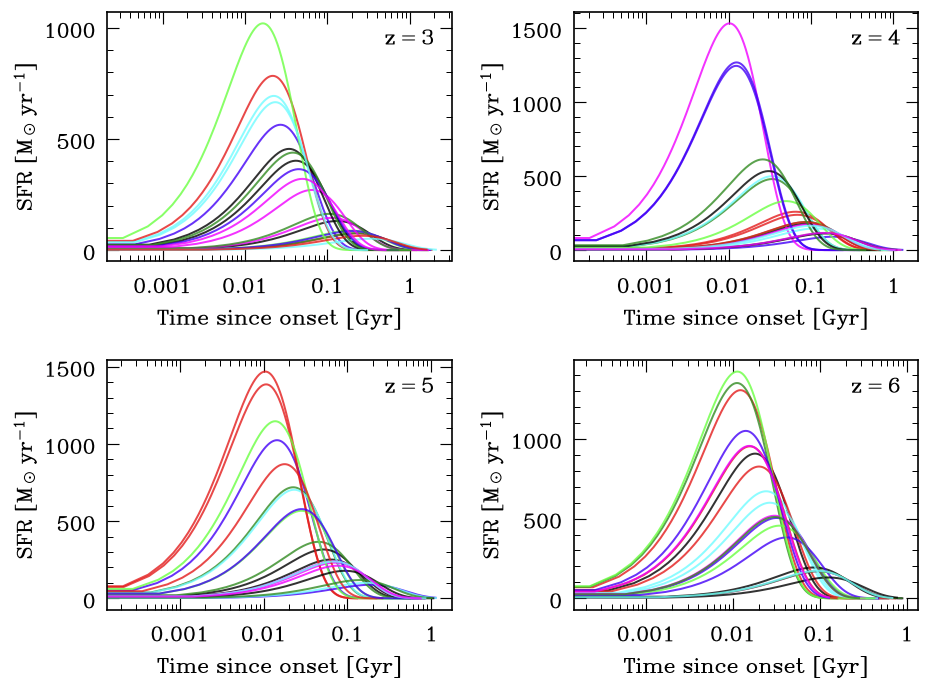

In [94]:
# Plot the sampled histories and observer-frame spectra in separate redshift panels.
z_plot_values = np.arange(z_min, z_max + 1, 1, dtype=float)
fig, axes = plt.subplots(2, 2, figsize=(8, 6))

for ax, z in zip(axes.flat, z_plot_values):
    for model in mock_models[z]:
        ax.plot(model["time_since_formation"], model["sfr_history"], alpha=0.8, lw=1.2)
    
    ax.set_ylabel(r"SFR [$M_\odot\,\mathrm{yr}^{-1}$]")
    ax.set_xlabel("Time since onset [Gyr]")
    ax.text(0.95, 0.95, rf"$z={z:.0f}$", transform=ax.transAxes, va="top", ha="right")
    ax.set_xscale("log")

fig.tight_layout()


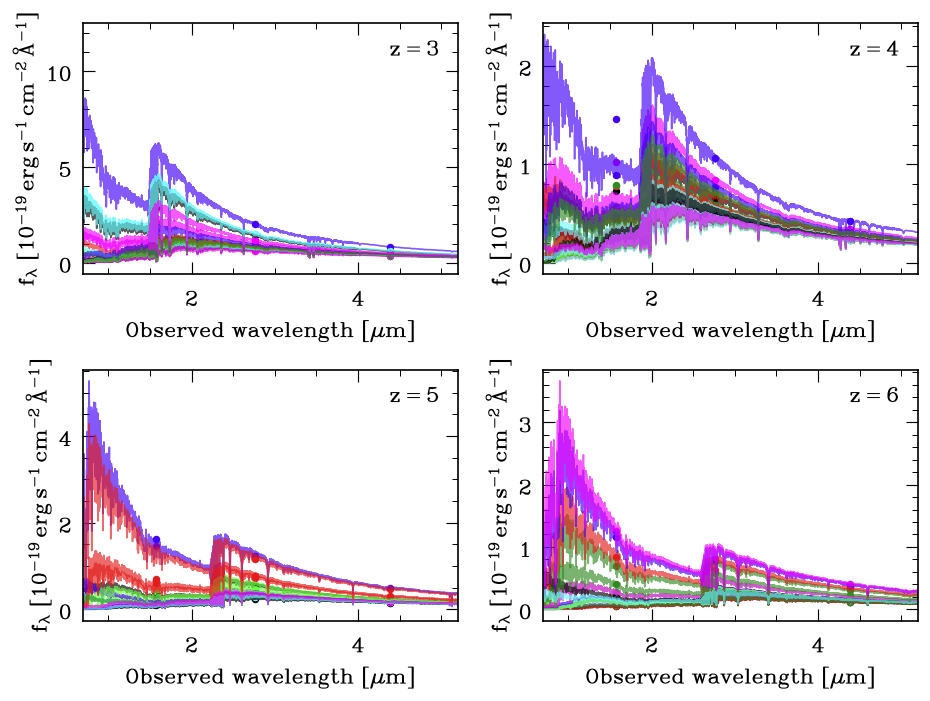

In [95]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, z in zip(axes.flat, z_plot_values):
    for model in mock_models[z]:
        wave_obs_um = convert_wave(model["wave_obs_aa"], u.AA, u.um)
        filter_wave_um = convert_wave(model["filter_wave_aa"], u.AA, u.um)
        line, = ax.plot(wave_obs_um, model["flux_obs_cgs_per_aa"] * 1e19, alpha=0.65, lw=1.0)
        ax.scatter(filter_wave_um, model["sed_f_lambda_cgs_per_aa"] * 1e19, s=12, color=line.get_color())
    ax.text(0.95, 0.95, rf"$z={z:.0f}$", transform=ax.transAxes, va="top", ha="right")
    ax.set_xlim(0.7, 5.2)

    ax.set_xlabel(r"Observed wavelength [$\mu$m]")
    ax.set_ylabel(r"$f_\lambda$ [$10^{-19}\,\mathrm{erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$]")

fig.tight_layout()

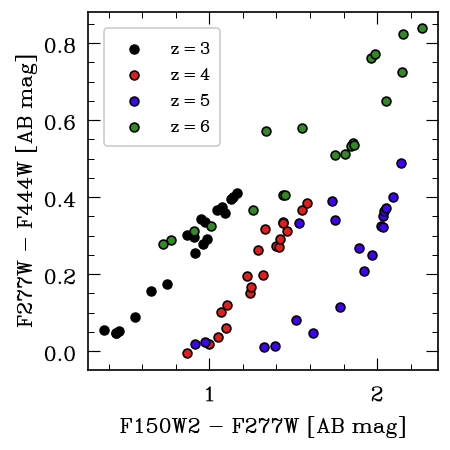

In [96]:
# Show F150W2 - F277W against F277W - F444W.
fig, ax = plt.subplots(figsize=(4, 4))
for z, models in mock_models.items():
    colours = np.array([model["colors"]["f150w2"] for model in models])
    ax.scatter(colours[:, 0], colours[:, 1], s=28, label=rf"$z={z:.0f}$")
ax.set_xlabel("F150W2 - F277W [AB mag]")
ax.set_ylabel("F277W - F444W [AB mag]")
ax.legend(frameon=True, fontsize=12)
fig.tight_layout()


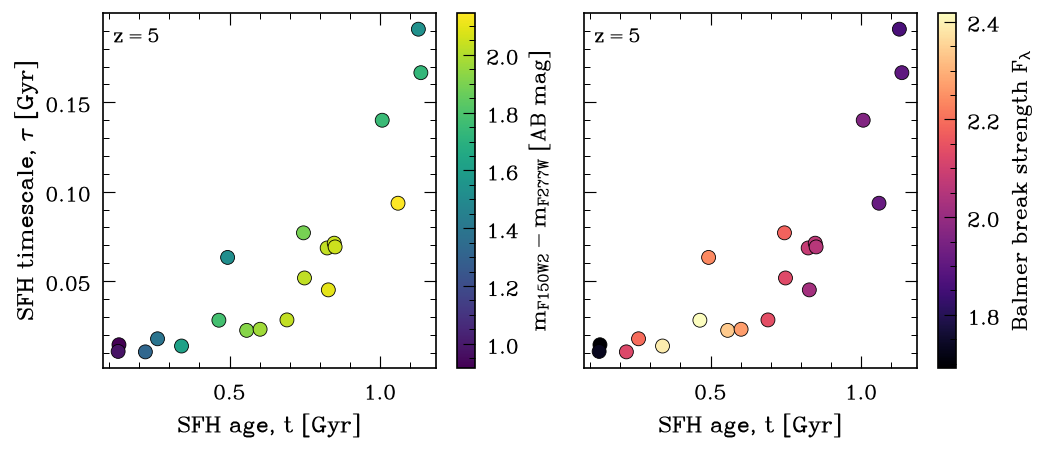

In [97]:
# Wang+24 wavelength windows, measured here in intrinsic template F_lambda without Prism smoothing or noise.
BREAK_PLOT_REDSHIFT = 5.0
break_models = mock_models[BREAK_PLOT_REDSHIFT]
ages = np.array([model["t_galaxy"] for model in break_models])
taus = np.array([model["tau"] for model in break_models])
colour_values = np.array([model["balmer_break_colour_mag"] for model in break_models])
break_values = np.array([model["balmer_break_wang24_flambda_ratio"] for model in break_models])

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
colour_points = axes[0].scatter(ages, taus, c=colour_values, cmap="viridis", s=70, edgecolor="black", linewidth=0.5)
break_points = axes[1].scatter(ages, taus, c=break_values, cmap="magma", s=70, edgecolor="black", linewidth=0.5)

for ax in axes:
    ax.set_xlabel(r"SFH age, $t$ [Gyr]", fontsize=16)
    ax.text(0.03, 0.97, f"$z={BREAK_PLOT_REDSHIFT:.0f}$", fontsize=14, transform=ax.transAxes, va="top", ha="left")

axes[0].set_ylabel(r"SFH timescale, $\tau$ [Gyr]", fontsize=16)

fig.colorbar(colour_points, ax=axes[0], label="$m_{\mathrm{F150W2}} - m_{\mathrm{F277W}}$ [AB mag]")
fig.colorbar(break_points, ax=axes[1], label=r"Balmer break strength $F_\lambda$")
fig.tight_layout()
